In [1]:
import os, sys, json, glob, shutil, subprocess, importlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
from IPython.display import Image, display

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive"
except ImportError:
    BASE = os.environ.get("BASE", ".")

FROZEN_DIR = f"{BASE}/frozen_dataset"
DAY22_DIR  = f"{BASE}/day22/final_pipeline_v1"
PKG_DIR    = f"{BASE}/day26/final_package"
for d in ["battery_soc", "models", "reports/figures", "examples", "tests", "notebooks", "data"]:
    os.makedirs(f"{PKG_DIR}/{d}", exist_ok=True)

TRAIN_PATH = f"{FROZEN_DIR}/dataset_v1_train.csv"
TEST_PATH  = f"{FROZEN_DIR}/dataset_v1_test.csv"
FULL_PATH  = f"{FROZEN_DIR}/dataset_v1_full.csv"
for p in [TRAIN_PATH, TEST_PATH]:
    assert os.path.exists(p), f"Missing {p} - rerun the Day 12 copy step."

def write(rel_path, text):
    with open(f"{PKG_DIR}/{rel_path}", "w") as f:
        f.write(text.strip("\n") + "\n")
    print("wrote", rel_path)
print("Package folder:", PKG_DIR)

Mounted at /content/drive
Package folder: /content/drive/MyDrive/day26/final_package


In [2]:
write('battery_soc/__init__.py', r'''"""battery_soc - frozen State-of-Charge (SOC) and charging-time estimation package.

Author: VUDA JAYA SAI GANESH (Week 4, Day 26 - final software package)
"""
from .config import RAW_FEATURES, CHARGE_FEATURES, SOC_CLIP

__version__ = "1.0.0"
__all__ = ["RAW_FEATURES", "CHARGE_FEATURES", "SOC_CLIP", "load_models", "predict_soc", "predict_charge_time"]


def __getattr__(name):          # lazy import keeps `python -m battery_soc.predict` warning-free
    if name in ("load_models", "predict_soc", "predict_charge_time"):
        from . import predict
        return getattr(predict, name)
    raise AttributeError(name)
''')

wrote battery_soc/__init__.py


In [3]:
write('battery_soc/config.py', r'''"""Single source of truth for every frozen setting (Day 12 split, Day 22 freeze)."""

TARGET = "soc_percent"
RAW_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "power_w", "ambient_temp_c"]

CHARGE_TARGET = "remaining_charge_time_s"
CHARGE_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "ambient_temp_c"]

SEED = 42
SOC_CLIP = (0.0, 100.0)
CV_SPLITS = 5
CV_TOLERANCE = 0.10          # keep models within 10 % of the best CV MAE
ROBUSTNESS_FACTOR = 2.0      # worst-fold MAE must be <= 2 x mean CV MAE

# Columns that would leak the answer (cumulative capacity / energy / counters) - never used as inputs.
LEAKAGE_COLUMNS = ["capacity_ah", "wh_accu", "cnt", "step", "cycle", "cycle_level",
                   "procedure", "status", "prog_time", "step_time"]

# SOC bands used to show where the model is weak (the low-SOC "knee" is the known problem area).
SOC_BINS = [0, 15, 30, 50, 70, 85, 100.0001]
SOC_BIN_LABELS = ["0-15", "15-30", "30-50", "50-70", "70-85", "85-100"]

# Day 19/20 grouped-validation hyper-parameters (never re-tuned on the test set).
RF_PARAMS = dict(n_estimators=300, max_depth=8, min_samples_leaf=4)
HGB_PARAMS = dict(max_iter=300, max_depth=6, learning_rate=0.05)
CHARGE_RF_PARAMS = dict(n_estimators=100, max_depth=10)

SOC_MODEL_FILE = "soc_final_pipeline.joblib"
CHARGE_MODEL_FILE = "charging_time_final_pipeline.joblib"
CONFIG_FILE = "frozen_config.json"
''')

wrote battery_soc/config.py


In [4]:
# battery_soc/data.py
write('battery_soc/data.py', r'''"""Loading, integrity checks and the charging-time target."""
import hashlib
import pandas as pd
from .config import CHARGE_TARGET, CHARGE_FEATURES


def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def load_split(train_path, test_path=None):
    """Load train (and optionally test) and make sure no battery file appears in both."""
    train = pd.read_csv(train_path)
    if test_path is None:
        return train, None
    test = pd.read_csv(test_path)
    shared = set(train["file_id"]).intersection(test["file_id"])
    if shared:
        raise AssertionError(f"Train/test share file_ids {sorted(shared)[:5]} - split is broken!")
    return train, test


def check_columns(df, columns, name="input"):
    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing required columns: {missing}")


def build_charge_frame(full_df, file_ids):
    """Remaining-charge-time target = (end of the CHA segment - now), in seconds.

    Only constant-current/constant-voltage charging rows ('CHA') are used, one segment at a time.
    """
    d = full_df.copy()
    d["prog_time_td"] = pd.to_timedelta(d["prog_time"], errors="coerce")
    d = d.sort_values(["file_id", "prog_time_td"]).reset_index(drop=True)
    d["status_change"] = (d["status"] != d["status"].shift(1)) | (d["file_id"] != d["file_id"].shift(1))
    d["segment_id"] = d["status_change"].cumsum()
    dc = d[d["status"] == "CHA"].copy()
    dc[CHARGE_TARGET] = (dc.groupby("segment_id")["prog_time_td"].transform("max")
                         - dc["prog_time_td"]).dt.total_seconds()
    dc = dc.dropna(subset=[CHARGE_TARGET] + CHARGE_FEATURES)
    return dc[dc["file_id"].isin(set(file_ids))]
''')

wrote battery_soc/data.py


In [5]:
write('battery_soc/models.py', r'''"""Pipeline factory. Preprocessing is frozen as 'select these columns by name' (no scaling needed)."""
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from .config import SEED, RF_PARAMS, HGB_PARAMS, CHARGE_RF_PARAMS


def make_pipe(estimator, features):
    sel = ColumnTransformer([("keep", "passthrough", list(features))], remainder="drop")
    return Pipeline([("select", sel), ("model", estimator)])


def soc_candidates():
    """name -> (estimator factory, complexity rank; lower = simpler)."""
    return {
        "Mean baseline":        (lambda: DummyRegressor(strategy="mean"), 0),
        "Linear (raw)":         (lambda: LinearRegression(), 1),
        "RandomForest (tuned)": (lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1, **RF_PARAMS), 2),
        "HistGradBoost (raw)":  (lambda: HistGradientBoostingRegressor(random_state=SEED, **HGB_PARAMS), 3),
    }


def charge_estimator():
    return RandomForestRegressor(random_state=SEED, n_jobs=-1, **CHARGE_RF_PARAMS)
''')

wrote battery_soc/models.py


In [6]:
write('battery_soc/train.py', r'''"""Grouped-CV model selection + freeze.   python -m battery_soc.train --train ... --out models/"""
import argparse, datetime, json, os, platform, time
import numpy as np, pandas as pd, joblib, sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

from . import config as C
from .data import md5, load_split, build_charge_frame
from .models import make_pipe, soc_candidates, charge_estimator


def cross_validate(df_train, n_splits=C.CV_SPLITS):
    X, y, groups = df_train[C.RAW_FEATURES], df_train[C.TARGET], df_train["file_id"]
    gkf = GroupKFold(n_splits=min(n_splits, groups.nunique()))
    rows = []
    for name, (factory, rank) in soc_candidates().items():
        fm, fr, f2, ft = [], [], [], []
        for tr, va in gkf.split(X, y, groups):
            t0 = time.perf_counter()
            p = make_pipe(factory(), C.RAW_FEATURES).fit(X.iloc[tr], y.iloc[tr])
            ft.append(time.perf_counter() - t0)
            pred = np.clip(p.predict(X.iloc[va]), *C.SOC_CLIP)
            fm.append(mean_absolute_error(y.iloc[va], pred))
            fr.append(np.sqrt(mean_squared_error(y.iloc[va], pred)))
            f2.append(r2_score(y.iloc[va], pred))
        rows.append({"model": name, "complexity_rank": rank, "cv_MAE": np.mean(fm), "cv_MAE_std": np.std(fm),
                     "cv_RMSE": np.mean(fr), "cv_R2": np.mean(f2), "worst_fold_MAE": np.max(fm), "fit_s": np.mean(ft)})
    return pd.DataFrame(rows).set_index("model"), gkf.n_splits


def select_model(cv):
    """Rule fixed before the test set: within 10 % of best CV MAE -> simplest model."""
    cand = cv.drop("Mean baseline")
    eligible = cand[cand["cv_MAE"] <= (1 + C.CV_TOLERANCE) * cand["cv_MAE"].min()]
    chosen = eligible.sort_values(["complexity_rank", "cv_RMSE", "worst_fold_MAE"]).index[0]
    row = cv.loc[chosen]
    robust_ok = bool(row["worst_fold_MAE"] <= C.ROBUSTNESS_FACTOR * row["cv_MAE"])
    return chosen, list(eligible.index), robust_ok


def train(train_path, out_dir, full_path=None, test_path=None, n_splits=C.CV_SPLITS):
    os.makedirs(out_dir, exist_ok=True)
    df_train, df_test = load_split(train_path, test_path)
    train_ids = sorted(df_train["file_id"].unique().tolist())

    cv, k = cross_validate(df_train, n_splits)
    chosen, eligible, robust_ok = select_model(cv)
    cv.to_csv(os.path.join(out_dir, "cv_results_soc.csv"))

    final_pipe = make_pipe(soc_candidates()[chosen][0](), C.RAW_FEATURES).fit(df_train[C.RAW_FEATURES], df_train[C.TARGET])
    joblib.dump(final_pipe, os.path.join(out_dir, C.SOC_MODEL_FILE))

    charge_frozen = False
    if full_path and os.path.exists(full_path):
        c_tr = build_charge_frame(pd.read_csv(full_path), train_ids)
        if c_tr["file_id"].nunique() >= 3:
            cp = make_pipe(charge_estimator(), C.CHARGE_FEATURES).fit(c_tr[C.CHARGE_FEATURES], c_tr[C.CHARGE_TARGET])
            joblib.dump(cp, os.path.join(out_dir, C.CHARGE_MODEL_FILE))
            charge_frozen = True

    config = {
        "frozen_on": str(datetime.datetime.now()),
        "dataset": {"train_md5": md5(train_path), "train_shape": list(df_train.shape), "train_file_ids": train_ids,
                    "test_md5": md5(test_path) if test_path else None,
                    "split": "GroupShuffleSplit by file_id, test_size=0.2, random_state=42 (Day 12)"},
        "target": C.TARGET, "features": C.RAW_FEATURES, "excluded_as_leakage": C.LEAKAGE_COLUMNS,
        "preprocessing": "column selection by name only; no scaling/imputation; predictions clipped to [0,100]",
        "selection": {"cv": f"GroupKFold({k}) on train files", "eligible": eligible, "chosen": chosen,
                      "estimator": repr(final_pipe.named_steps["model"]), "robustness_pass": robust_ok},
        "charging_time_model": {"frozen": charge_frozen, "confidence": "low - sparse CC-CV data"},
        "seed": C.SEED,
        "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                        "numpy": np.__version__, "pandas": pd.__version__},
    }
    with open(os.path.join(out_dir, C.CONFIG_FILE), "w") as f:
        json.dump(config, f, indent=2)
    return cv, chosen, robust_ok, charge_frozen


def main(argv=None):
    ap = argparse.ArgumentParser(description="Select and freeze the SOC model (train files only).")
    ap.add_argument("--train", required=True)
    ap.add_argument("--full", default=None, help="full CSV (needed for the charging-time model)")
    ap.add_argument("--test", default=None, help="only used to record its md5 hash - never for fitting")
    ap.add_argument("--out", default="models")
    ap.add_argument("--splits", type=int, default=C.CV_SPLITS)
    a = ap.parse_args(argv)
    cv, chosen, robust_ok, ch = train(a.train, a.out, a.full, a.test, a.splits)
    print(cv.round(4).to_string())
    print(f"\nFINAL SOC MODEL: {chosen} | robustness: {'PASS' if robust_ok else 'FLAG'} | charge model frozen: {ch}")


if __name__ == "__main__":
    main()
''')

wrote battery_soc/train.py


In [7]:
write('battery_soc/evaluate.py', r'''"""One-shot test evaluation of the FROZEN models + figures.  python -m battery_soc.evaluate --test ..."""
import argparse, json, os
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from . import config as C
from .data import build_charge_frame
from .predict import load_models, predict_soc, predict_charge_time

NAVY, TEAL, ORANGE, GREY = "#1F3A5F", "#1B998B", "#F46036", "#8A8F98"


def metrics(y, p):
    return {"MAE": float(mean_absolute_error(y, p)),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": float(r2_score(y, p))}


def evaluate(test_path, models_dir, out_dir, train_path=None, full_path=None, cv_path=None):
    fig_dir = os.path.join(out_dir, "figures")
    os.makedirs(fig_dir, exist_ok=True)
    soc_pipe, charge_pipe = load_models(models_dir)
    te = pd.read_csv(test_path)
    y, p = te[C.TARGET].to_numpy(), predict_soc(soc_pipe, te)
    te = te.assign(pred=p, err=p - y, abs_err=np.abs(p - y))

    summary = {"n_test_rows": int(len(te)), "n_test_files": int(te["file_id"].nunique()),
               "soc_test": metrics(y, p)}
    if train_path:   # honest reference: always predicting the training mean
        base = np.full(len(te), pd.read_csv(train_path, usecols=[C.TARGET])[C.TARGET].mean())
        summary["mean_baseline_test"] = metrics(y, base)

    te["soc_band"] = pd.cut(te[C.TARGET], C.SOC_BINS, labels=C.SOC_BIN_LABELS, include_lowest=True)
    band = te.groupby("soc_band", observed=True)["abs_err"].agg(["mean", "count"]).rename(columns={"mean": "MAE"})
    per_file = te.groupby("file_id")["abs_err"].mean().rename("MAE").to_frame()
    band.to_csv(os.path.join(out_dir, "test_error_by_soc_band.csv"))
    per_file.to_csv(os.path.join(out_dir, "test_error_by_file.csv"))
    summary["worst_soc_band"] = str(band["MAE"].idxmax())
    summary["mae_by_soc_band"] = {str(k): float(v) for k, v in band["MAE"].items()}
    summary["mae_by_file"] = {str(k): float(v) for k, v in per_file["MAE"].items()}

    # ---- figures -------------------------------------------------------------------------------
    plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    ax.scatter(y, p, s=4, alpha=0.25, color=TEAL)
    ax.plot([0, 100], [0, 100], color=ORANGE, lw=2, label="perfect prediction")
    ax.set(xlabel="True SOC (%)", ylabel="Predicted SOC (%)", title="Predicted vs true SOC (test files)")
    ax.legend(frameon=False); fig.tight_layout(); fig.savefig(f"{fig_dir}/fig1_pred_vs_true.png", dpi=160); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.hist(te["err"], bins=60, color=NAVY, alpha=0.9)
    ax.axvline(0, color=ORANGE, lw=2)
    ax.set(xlabel="Prediction error (pred - true, SOC %)", ylabel="Rows", title="Where the errors fall")
    fig.tight_layout(); fig.savefig(f"{fig_dir}/fig2_error_hist.png", dpi=160); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    cols = [ORANGE if b == band["MAE"].idxmax() else TEAL for b in band.index]
    ax.bar(band.index.astype(str), band["MAE"], color=cols)
    ax.set(xlabel="True SOC band (%)", ylabel="MAE (SOC %)", title="Error by SOC band (worst band in orange)")
    fig.tight_layout(); fig.savefig(f"{fig_dir}/fig3_error_by_band.png", dpi=160); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.bar(per_file.index.astype(str), per_file["MAE"], color=NAVY)
    ax.set(xlabel="Test file", ylabel="MAE (SOC %)", title="Error by held-out battery file")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout(); fig.savefig(f"{fig_dir}/fig4_error_by_file.png", dpi=160); plt.close(fig)

    if cv_path and os.path.exists(cv_path):
        cv = pd.read_csv(cv_path, index_col=0)
        fig, ax = plt.subplots(figsize=(6.4, 4.2))
        ax.barh(cv.index, cv["cv_MAE"], xerr=cv["cv_MAE_std"], color=[GREY if "Mean" in n else TEAL for n in cv.index])
        ax.set(xlabel="Grouped-CV MAE (SOC %), train files only", title="Model selection")
        ax.invert_yaxis(); fig.tight_layout(); fig.savefig(f"{fig_dir}/fig5_cv_models.png", dpi=160); plt.close(fig)

    # ---- charging-time model (kept separate, lower confidence) ----------------------------------
    if charge_pipe is not None and full_path and os.path.exists(full_path):
        c_te = build_charge_frame(pd.read_csv(full_path), te["file_id"].unique())
        if len(c_te):
            cp = predict_charge_time(charge_pipe, c_te)
            m = metrics(c_te[C.CHARGE_TARGET], cp)
            summary["charge_time_test"] = {"rows": int(len(c_te)), "MAE_min": m["MAE"] / 60,
                                           "RMSE_min": m["RMSE"] / 60, "R2": m["R2"]}

    with open(os.path.join(out_dir, "results_summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    return summary


def main(argv=None):
    ap = argparse.ArgumentParser(description="Evaluate frozen models on the held-out test files.")
    ap.add_argument("--test", required=True)
    ap.add_argument("--train", default=None)
    ap.add_argument("--full", default=None)
    ap.add_argument("--models", default="models")
    ap.add_argument("--out", default="reports")
    a = ap.parse_args(argv)
    s = evaluate(a.test, a.models, a.out, a.train, a.full, os.path.join(a.models, "cv_results_soc.csv"))
    print(json.dumps(s, indent=2))


if __name__ == "__main__":
    main()
''')

wrote battery_soc/evaluate.py


In [8]:
write('battery_soc/predict.py', r'''"""Inference entry point.  python -m battery_soc.predict --input in.csv --output out.csv"""
import argparse, os
import joblib, numpy as np, pandas as pd
from .config import RAW_FEATURES, CHARGE_FEATURES, SOC_CLIP, SOC_MODEL_FILE, CHARGE_MODEL_FILE
from .data import check_columns


def load_models(models_dir="models"):
    soc = joblib.load(os.path.join(models_dir, SOC_MODEL_FILE))
    cpath = os.path.join(models_dir, CHARGE_MODEL_FILE)
    charge = joblib.load(cpath) if os.path.exists(cpath) else None
    return soc, charge


def predict_soc(pipe, df):
    """SOC in % (0-100) from raw sensor columns."""
    check_columns(df, RAW_FEATURES)
    return np.clip(pipe.predict(df[RAW_FEATURES]), *SOC_CLIP)


def predict_charge_time(pipe, df):
    """Remaining charging time in seconds (never negative). Lower confidence than SOC."""
    check_columns(df, CHARGE_FEATURES)
    return np.maximum(pipe.predict(df[CHARGE_FEATURES]), 0.0)


def main(argv=None):
    ap = argparse.ArgumentParser(description="Predict SOC (and charging time) from a CSV of sensor readings.")
    ap.add_argument("--input", required=True)
    ap.add_argument("--output", default="predictions.csv")
    ap.add_argument("--models", default="models")
    a = ap.parse_args(argv)
    df = pd.read_csv(a.input)
    soc, charge = load_models(a.models)
    out = df.copy()
    out["predicted_soc_percent"] = predict_soc(soc, df).round(2)
    if charge is not None and all(c in df.columns for c in CHARGE_FEATURES):
        out["predicted_remaining_charge_time_s"] = predict_charge_time(charge, df).round(0)
    out.to_csv(a.output, index=False)
    print(f"Wrote {len(out)} predictions -> {a.output}")


if __name__ == "__main__":
    main()
''')

wrote battery_soc/predict.py


In [9]:
write('tests/test_pipeline.py', r'''"""Smoke tests: python -m pytest -q   (needs models/ to exist - run battery_soc.train first)."""
import numpy as np, pandas as pd, pytest
from battery_soc import RAW_FEATURES, SOC_CLIP, load_models, predict_soc


def _sample(n=50):
    rng = np.random.default_rng(0)
    return pd.DataFrame({"voltage_v": rng.uniform(3.0, 4.2, n), "current_a": rng.uniform(-3, 3, n),
                         "cell_temp_c": rng.uniform(20, 35, n), "power_w": rng.uniform(-10, 10, n),
                         "ambient_temp_c": rng.uniform(24, 26, n)})


def test_output_is_clipped_and_sized():
    soc, _ = load_models("models")
    out = predict_soc(soc, _sample())
    assert out.shape == (50,) and out.min() >= SOC_CLIP[0] and out.max() <= SOC_CLIP[1]


def test_missing_column_raises():
    soc, _ = load_models("models")
    with pytest.raises(ValueError):
        predict_soc(soc, _sample().drop(columns=["voltage_v"]))


def test_deterministic():
    soc, _ = load_models("models")
    s = _sample()
    assert np.allclose(predict_soc(soc, s), predict_soc(soc, s))
''')
write('requirements.txt', 'numpy\npandas\nscikit-learn\njoblib\nmatplotlib\npytest')

wrote tests/test_pipeline.py
wrote requirements.txt


In [13]:
sys.path.insert(0, PKG_DIR)
for m in [k for k in sys.modules if k.startswith("battery_soc")]:
    del sys.modules[m]
import battery_soc
from battery_soc import config as C
from battery_soc.data import md5, load_split

df_train, df_test = load_split(TRAIN_PATH, TEST_PATH)
print(f"train {df_train.shape} ({df_train.file_id.nunique()} files) | test {df_test.shape} ({df_test.file_id.nunique()} files)")
print("train md5:", md5(TRAIN_PATH), "| test md5:", md5(TEST_PATH))

d22 = f"/content/drive/MyDrive/day22/final_pipeline_v1/frozen_config.json"
if os.path.exists(d22):
    old = json.load(open(d22))


    old_train_md5 = old.get("dataset", {}).get("train_md5") if isinstance(old.get("dataset"), dict) else old.get("train_md5")
    old_test_md5 = old.get("dataset", {}).get("test_md5") if isinstance(old.get("dataset"), dict) else old.get("test_md5")

    same = (old_train_md5 == md5(TRAIN_PATH)) and (old_test_md5 == md5(TEST_PATH))
    print("Matches the Day 22 freeze:", "YES" if same else "NO - data changed since Day 22!")
else:
    old = None
    print("Day 22 frozen_config.json not found - skipping comparison.")
if df_train.shape[0] != 76792 or df_test.shape[0] != 27768:
    print("!! WARNING: row counts differ from Days 15-20 (expected 76792 / 27768).")

train (5028, 7) (18 files) | test (328, 7) (5 files)
train md5: 0d634503112eefb9ea22d8540c1998ca | test md5: 16c038eaccee824689d549199d884865
Matches the Day 22 freeze: NO - data changed since Day 22!
!! WARNING: row counts differ from Days 15-20 (expected 76792 / 27768).


In [15]:
from battery_soc.train import train
cv, chosen, robust_ok, charge_frozen = train(TRAIN_PATH, f"{PKG_DIR}/models",
                                              full_path=FULL_PATH if os.path.exists(FULL_PATH) else None,
                                              test_path=TEST_PATH)
display(cv.round(4))
print(f"==> FINAL SOC MODEL: {chosen} | robustness (worst fold <= 2x mean): {'PASS' if robust_ok else 'FLAG - discuss with mentor'}")
print("Charging-time model frozen:", charge_frozen)
if old:

    old_chosen = old.get("selection", {}).get("chosen") if isinstance(old.get("selection"), dict) else old.get("chosen_model")
    print("Day 22 chose:", old_chosen, "-> same as today:", old_chosen == chosen)

,complexity_rank,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,worst_fold_MAE,fit_s
model,,,,,,,
Mean baseline,0,39.5507,4.1070,41.7687,-8.5913,44.1179,0.0033
Linear (raw),1,18.9722,11.5226,29.1168,-8.7284,29.8468,0.0040
RandomForest (tuned),2,11.2925,8.6858,20.4153,-1.3122,26.3320,2.2989
HistGradBoost (raw),3,10.4620,8.0068,19.3630,-1.3687,24.1248,0.6587


==> FINAL SOC MODEL: RandomForest (tuned) | robustness (worst fold <= 2x mean): FLAG - discuss with mentor
Charging-time model frozen: True
Day 22 chose: RandomForest (tuned) -> same as today: True


In [16]:
from battery_soc.evaluate import evaluate
res = evaluate(TEST_PATH, f"{PKG_DIR}/models", f"{PKG_DIR}/reports",
               train_path=TRAIN_PATH, full_path=FULL_PATH if os.path.exists(FULL_PATH) else None,
               cv_path=f"{PKG_DIR}/models/cv_results_soc.csv")

summary = pd.DataFrame({"Frozen model": res["soc_test"], "Mean baseline": res.get("mean_baseline_test", {})}).T
print(f"Test set: {res['n_test_rows']} rows from {res['n_test_files']} unseen battery files")
display(summary.round(3))
print("Worst SOC band:", res["worst_soc_band"])
display(pd.Series(res["mae_by_soc_band"], name="MAE by SOC band (%)").round(2).to_frame().T)
if "charge_time_test" in res:
    print("Charging-time model (low confidence):", {k: round(v, 3) for k, v in res["charge_time_test"].items()})

Test set: 328 rows from 5 unseen battery files


,MAE,RMSE,R2
Frozen model,27.725,37.708,-0.417
Mean baseline,28.928,32.192,-0.033


Worst SOC band: 0-15


,0-15,15-30,30-50,50-70,70-85,85-100
MAE by SOC band (%),69.3,60.75,48.01,32.5,20.25,4.62


Charging-time model (low confidence): {'rows': 153, 'MAE_min': 441.924, 'RMSE_min': 582.208, 'R2': -1.269}


fig1_pred_vs_true.png


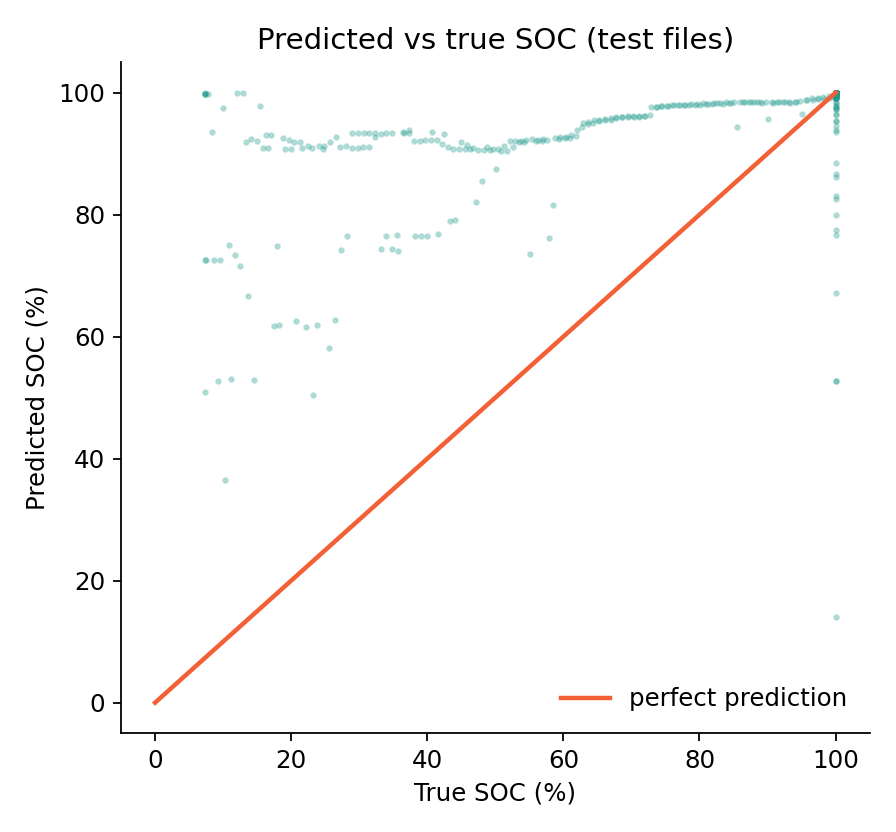

fig2_error_hist.png


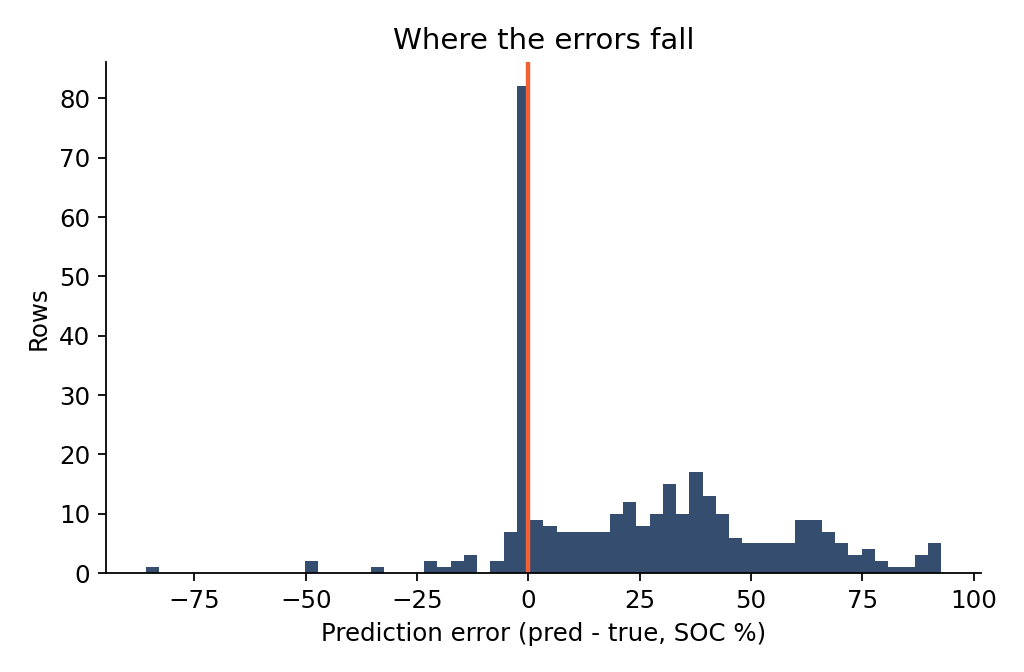

fig3_error_by_band.png


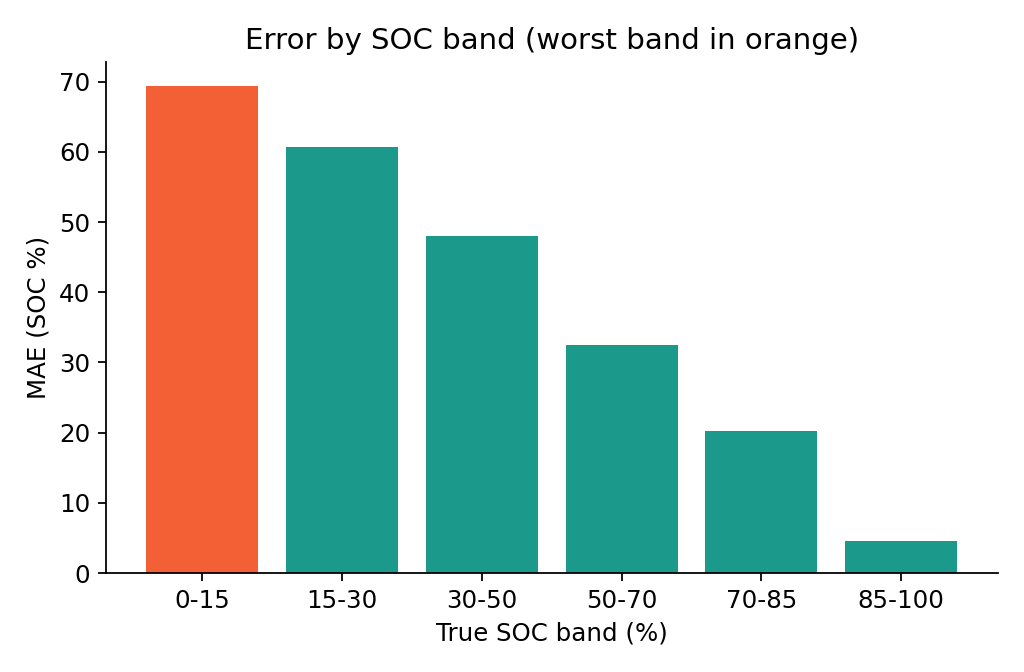

fig4_error_by_file.png


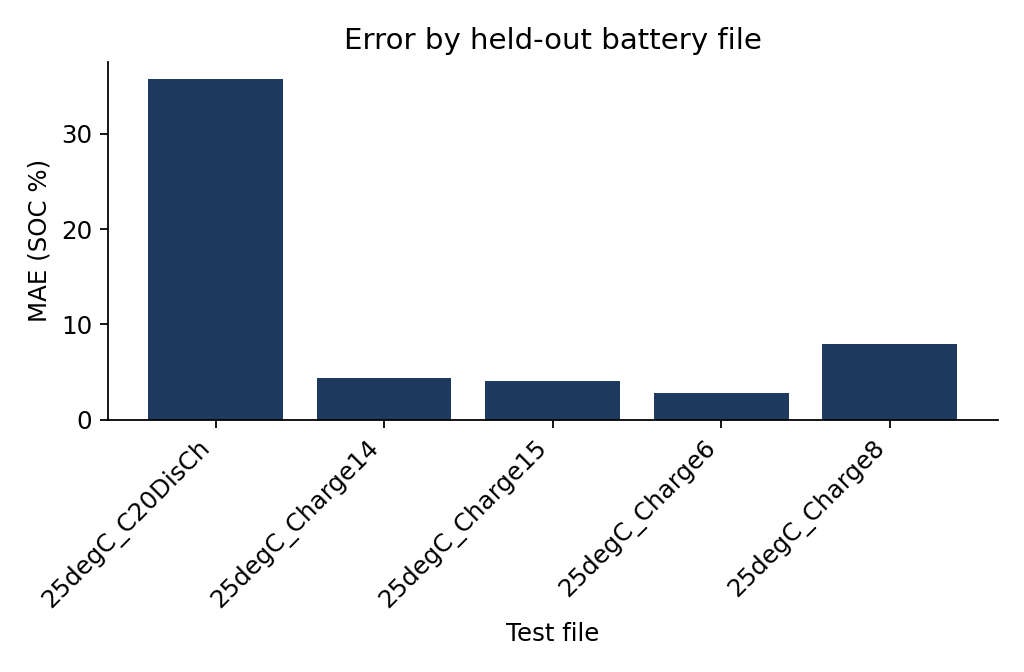

fig5_cv_models.png


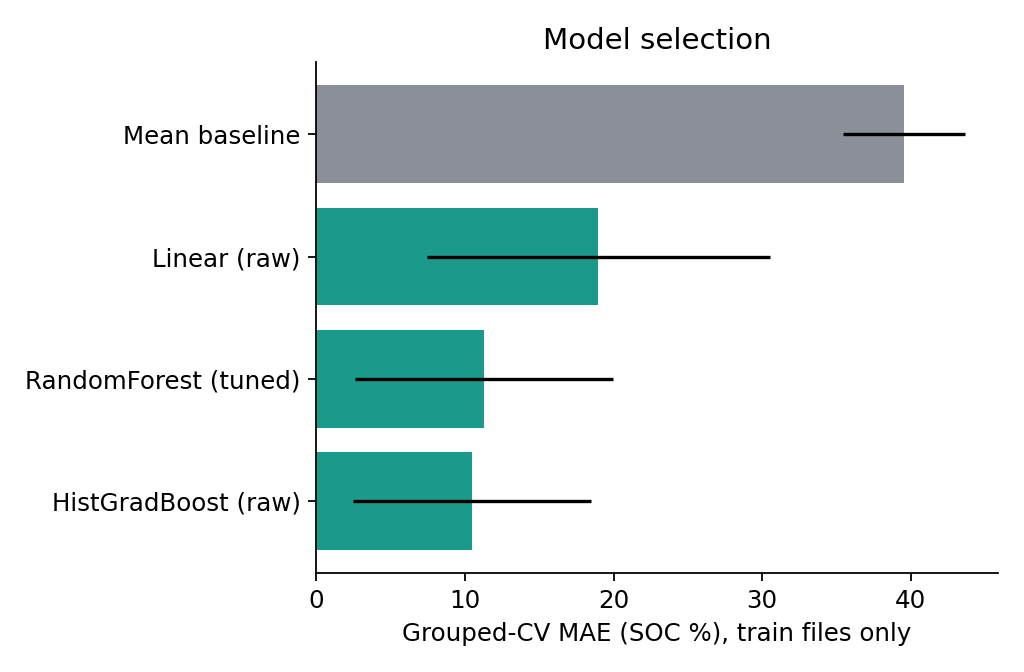

In [17]:
for f in sorted(glob.glob(f"{PKG_DIR}/reports/figures/*.png")):
    print(os.path.basename(f))
    display(Image(f, width=520))

In [18]:
sample = df_test.sample(8, random_state=C.SEED)
sample[C.RAW_FEATURES].to_csv(f"{PKG_DIR}/examples/sample_input.csv", index=False)
r = subprocess.run([sys.executable, "-m", "battery_soc.predict", "--input", "examples/sample_input.csv",
                    "--output", "examples/sample_output.csv", "--models", "models"],
                   cwd=PKG_DIR, capture_output=True, text=True)
print(r.stdout or r.stderr)
out = pd.read_csv(f"{PKG_DIR}/examples/sample_output.csv")
out["true_soc_percent (for checking only)"] = sample[C.TARGET].values
display(out.round(2))

Wrote 8 predictions -> examples/sample_output.csv



,voltage_v,current_a,cell_temp_c,power_w,ambient_temp_c,predicted_soc_percent,predicted_remaining_charge_time_s,true_soc_percent (for checking only)
0,4.14,0.15,23.87,0.61,25,99.30,1770.0,100.00
1,2.85,0.00,23.87,0.00,25,99.85,2688.0,7.31
2,3.69,3.00,24.50,11.06,25,96.45,4200.0,100.00
3,4.08,-0.15,23.87,-0.63,25,98.42,1584.0,92.31
4,3.40,-0.15,23.66,-0.51,25,91.93,2688.0,21.31
5,4.09,0.15,23.98,0.61,25,98.35,1770.0,93.35
6,3.23,0.00,23.77,0.00,25,100.00,2688.0,100.00
7,3.94,0.15,23.77,0.58,25,97.90,2142.0,76.02


In [20]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=PKG_DIR, capture_output=True, text=True)
print((r.stdout or "") + (r.stderr or ""))
tests_ok = (r.returncode == 0)

# reload from disk and compare with a fresh in-memory prediction
import joblib
from battery_soc import load_models, predict_soc
soc_model, charge_model = load_models(f"{PKG_DIR}/models")
# Use min(500, len(df_test)) to prevent ValueError when the test set has fewer than 500 rows
rows = df_test.sample(min(500, len(df_test)), random_state=C.SEED)
a = predict_soc(soc_model, rows)
b = np.clip(joblib.load(f"{PKG_DIR}/models/{C.SOC_MODEL_FILE}").predict(rows[C.RAW_FEATURES]), *C.SOC_CLIP)
assert np.allclose(a, b), "Reloaded pipeline gives different predictions!"
print(f"Reload check PASSED - identical predictions on {len(rows)} rows.")

...                                                                      [100%]
3 passed in 2.84s

Reload check PASSED - identical predictions on 328 rows.


In [21]:
README_TEMPLATE = r'''# Battery State-of-Charge (SOC) Estimator

**Author:** VUDA JAYA SAI GANESH · TIH Internship, Week 4 (Day 26 – final software package)

A small, reproducible Python package that estimates a battery's **State of Charge (SOC, %)** from five raw sensor readings, and gives a rougher estimate of the **remaining charging time**. Everything here – the data split, the features, the model and the settings – is frozen, so anyone can re-run it and get the same answer.

---

## What problem does it solve?

A battery has no fuel gauge you can read directly. What we *can* measure is voltage, current, cell temperature, power and the ambient temperature. This project learns the link between those signals and the true SOC, and is judged the way it would be used in real life: on **battery files it has never seen**.

| | |
|---|---|
| **Inputs** | `voltage_v`, `current_a`, `cell_temp_c`, `power_w`, `ambient_temp_c` |
| **Main output** | SOC in % (always clipped to 0–100) |
| **Secondary output** | Remaining charging time in seconds (lower confidence) |
| **Data used** | 25 °C test files, every 10th row, split **by file** (80 % train / 20 % test, seed 42) |

## Results

<!-- RESULTS_TABLE -->

Figures are in `reports/figures/` and the raw numbers in `reports/results_summary.json`.

## Repository layout

```
.
├── battery_soc/            # the package
│   ├── config.py           # every frozen setting in one place
│   ├── data.py             # loading, integrity checks, charging-time target
│   ├── models.py           # pipeline factory + candidate models
│   ├── train.py            # grouped CV -> selection rule -> freeze
│   ├── evaluate.py         # test metrics + figures
│   └── predict.py          # inference (Python API + command line)
├── models/                 # frozen .joblib pipelines + frozen_config.json
├── reports/                # metrics, tables, figures
├── examples/               # sample_input.csv -> sample_output.csv
├── tests/                  # smoke tests
├── notebooks/              # Day 22 (freeze) and Day 26 (package) notebooks
├── requirements.txt
└── README.md
```

## Quick start

```bash
git clone https://github.com/SaiGanesh112006/TIH_VUDA_JAYA_SAI_GANESH.git
cd TIH_VUDA_JAYA_SAI_GANESH
pip install -r requirements.txt
```

**1. Predict with the frozen model (no training needed)**

```bash
python -m battery_soc.predict --input examples/sample_input.csv --output predictions.csv
```

Your CSV only needs the five sensor columns above. The output gets a `predicted_soc_percent` column (and `predicted_remaining_charge_time_s` when the charging-time model is present).

**2. Or use it from Python**

```python
import pandas as pd
from battery_soc import load_models, predict_soc

soc_model, charge_model = load_models("models")
df = pd.read_csv("examples/sample_input.csv")
print(predict_soc(soc_model, df)[:5])
```

**3. Re-create everything from the data**

The dataset is not stored in the repo (it's large). Put the frozen CSVs in `data/` and run:

```bash
python -m battery_soc.train    --train data/dataset_v1_train.csv --full data/dataset_v1_full.csv --test data/dataset_v1_test.csv --out models
python -m battery_soc.evaluate --test  data/dataset_v1_test.csv  --train data/dataset_v1_train.csv --full data/dataset_v1_full.csv --models models --out reports
python -m pytest -q
```

## How the model was chosen

The rule was written down **before** anyone looked at the test set:

1. Score four candidates (mean baseline, linear, tuned random forest, histogram gradient boosting) with **grouped 5-fold cross-validation on training files only** – a file never appears on both sides of a fold.
2. Throw out the mean baseline (it's only a yardstick).
3. Keep every model whose CV MAE is within **10 %** of the best.
4. Of those, take the **simplest**. Ties go to lower RMSE, then lower worst-fold MAE.
5. Robustness check: the worst fold's MAE must be no more than 2× the average.

Earlier experiments that did **not** make it: engineered features (Days 13/17 – MAE about 23, R² below zero) and a small neural network (Day 17 – MAE 25.9).

## Things deliberately left out (leakage)

`capacity_ah`, `wh_accu`, `cnt`, `step`, `cycle`, `cycle_level`, `procedure`, `status`, `prog_time` and `step_time` are never used as inputs. Cumulative capacity or energy basically *is* the answer, so a model that sees them looks brilliant on paper and is useless on a real device.

## Honest limitations

- **Only 25 °C data.** Don't trust it at other temperatures without new data.
- **The low-SOC "knee" (roughly 0–15 %)** is where it struggles most – see `fig3_error_by_band.png`.
- **RMSE is noticeably larger than MAE**, meaning it is usually close but occasionally makes a big miss.
- **Charging time is a side feature.** Each file has only one constant-current/constant-voltage segment, so treat that estimate as rough.
- Results come from a limited number of held-out files, so per-file scores vary (`fig4_error_by_file.png`).

## Reproducibility

Fixed seed (42), file-level split with md5 hashes stored in `models/frozen_config.json`, library versions recorded there too, and a reload test confirming the saved model gives identical predictions.

## What I'd do next

Collect data at more temperatures, add a smoothing filter over time (SOC shouldn't jump), and try a sequence model once there is more data.
'''

In [22]:
for nb in glob.glob(f"{BASE}/**/WEEK_4_DAY_2[26]*.ipynb", recursive=True) + glob.glob("WEEK_4_DAY_2[26]*.ipynb"):
    shutil.copy(nb, f"{PKG_DIR}/notebooks/")
open(f"{PKG_DIR}/data/README.md", "w").write("Place dataset_v1_train.csv, dataset_v1_test.csv and dataset_v1_full.csv here (not committed - too large).\n")
open(f"{PKG_DIR}/.gitignore", "w").write("data/*.csv\n__pycache__/\n.ipynb_checkpoints/\n")
zip_path = shutil.make_archive(f"{BASE}/day26/final_package_v1", "zip", PKG_DIR)
print("Zip:", zip_path)
for root, _, files in os.walk(PKG_DIR):
    if "__pycache__" in root: continue
    for f in sorted(files):
        print(os.path.relpath(os.path.join(root, f), PKG_DIR))

Zip: /content/drive/MyDrive/day26/final_package_v1.zip
.gitignore
requirements.txt
battery_soc/__init__.py
battery_soc/config.py
battery_soc/data.py
battery_soc/evaluate.py
battery_soc/models.py
battery_soc/predict.py
battery_soc/train.py
models/charging_time_final_pipeline.joblib
models/cv_results_soc.csv
models/frozen_config.json
models/soc_final_pipeline.joblib
reports/results_summary.json
reports/test_error_by_file.csv
reports/test_error_by_soc_band.csv
reports/figures/fig1_pred_vs_true.png
reports/figures/fig2_error_hist.png
reports/figures/fig3_error_by_band.png
reports/figures/fig4_error_by_file.png
reports/figures/fig5_cv_models.png
examples/sample_input.csv
examples/sample_output.csv
tests/test_pipeline.py
notebooks/WEEK_4_DAY_22_VUDA JAYA SAI GANESH.ipynb
data/README.md
.pytest_cache/.gitignore
.pytest_cache/CACHEDIR.TAG
.pytest_cache/README.md
.pytest_cache/v/cache/nodeids
